# Credit Card Fraud Prediction

**Research question:** How effectively can supervised machine learning models detect rare fraudulent credit card transactions while limiting incorrect fraud alerts?

**Problem statement:** Credit-card fraud represents a very small fraction of transactions. An accurate-looking classifier may simply label most payments as legitimate and miss fraudulent activity. This project studies how three classification approaches balance *fraud detection* (recall) with *the reliability of fraud alerts* (precision).

**Objective:** Explore the transaction data, address extreme class imbalance, compare Logistic Regression, Random Forest, and XGBoost on validation data, and evaluate the selected XGBoost model on a separate test set using the **fixed 0.50 decision threshold**.

**Notebook roadmap:** Dataset and problem context → data cleaning → exploratory data analysis → stratified splits and preprocessing → three model experiments → validation comparison → final XGBoost test evaluation → validation-versus-test comparison → limitations and conclusion.

## 1. Context, Problem Statement, and Research Objective

Card fraud detection is a **rare-event classification** problem. A model must recognise a very small number of fraudulent transactions among a large volume of legitimate payments. This introduces an important operational trade-off:

- A **false negative (FN)** is fraud classified as legitimate: potentially a missed opportunity to prevent financial loss.
- A **false positive (FP)** is a legitimate transaction classified as fraud: potentially an unnecessary review, user friction, or disrupted payment.

A model that predicts *every* transaction as legitimate will appear highly accurate, but will identify **no** fraud. Therefore, this project prioritises **fraud-class precision, recall, F1, and average precision (AP)** rather than accuracy alone. ROC-AUC is reported as a complementary, threshold-independent ranking metric.

**Scope:** Offline binary classification on an anonymised, historical public dataset. The notebook does not estimate actual financial losses, model a production alert queue, or demonstrate deployment. Statements about financial savings require additional assumptions and evaluation.


## 2. Dataset and Data Collection

**Source:** [Credit Card Fraud Detection dataset (ULB/Kaggle)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). This publicly distributed dataset contains European cardholder transactions collected over roughly **two days in September 2013**.

**Data dictionary:**

| Variable | Meaning | Relevance |
|---|---|---|
| `Class` | Binary target: `1` = fraudulent, `0` = legitimate | Classification label |
| `Time` | Seconds elapsed since the first transaction in the dataset | Temporal context, **not** calendar hour of day |
| `Amount` | Transaction amount | Monetary magnitude |
| `V1`–`V28` | Anonymised, PCA-transformed features | Transaction signal; original feature semantics unavailable |

**Original size (saved output):** 284,807 rows × 31 columns. Because the proprietary underlying attributes are anonymised, this project cannot explain what each PCA component means in business terms or evaluate demographic fairness from this dataset.

In [1]:
# loading dataset 

import pandas as pd 
df = pd.read_csv("creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
df.shape

(284807, 31)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

## 3. Data Cleaning and Integrity Checks

The initial checks establish the dataset shape, data types, missing values, duplicated records, and permitted ranges. The saved output reports **no missing values** and **1,081 exact duplicate rows**. These duplicate rows are removed in the existing code, leaving **283,726 transactions**.

**Note:** Identical rows are not always mistakes, as some genuine transactions may have the same details. Removing all duplicates also reduces the number of fraud cases from the commonly reported 492 to 473. This can change the balance between normal and fraudulent transactions and affect the model's performance results. 

The `Time` and `Amount` minimum checks show no negative values, but non-negative values alone do not establish that the dataset is free of all anomalies. Zero-amount observations may be legitimate events and should not be dropped without evidence.


In [4]:
# check for missing values
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [5]:
# check for duplicate values 
df.duplicated().sum()

np.int64(1081)

In [6]:
df = df.drop_duplicates().reset_index(drop=True)

In [7]:
# check for duplicate values 
df.duplicated().sum()

np.int64(0)

In [8]:
df["Class"].value_counts()

Class
0    283253
1       473
Name: count, dtype: int64

### 3.1 Class balance after deduplication

| Class | Count | Share |
|---|---:|---:|
| Legitimate (`0`) | 283,253 | 99.8333% |
| Fraud (`1`) | 473 | **0.1667%** |

This corresponds to approximately **1 fraudulent transaction per 600 transactions**. If a classifier predicted every observation as legitimate, its accuracy would be about **99.83%**, despite a fraud recall of **0%**. This is why accuracy is potentially misleading here.

The severe imbalance motivates stratified splitting, training-set-only resampling or weighting, probability/ranking metrics, and explicit examination of false alarms.


In [9]:
# checking for invalid values 
df["Amount"].min()

0.0

In [10]:
df["Time"].min()

0.0

## 4. Exploratory Data Analysis (EDA)

**EDA questions:** (1) Are transaction amounts heavy-tailed? (2) Do amount distributions differ between fraudulent and legitimate cases? (3) Does fraud frequency change over the observed time window? (4) Which anonymised components correlate with the target? (5) Are unusual amounts informative, and should they be removed?

EDA is used to describe patterns in the data rather than explain the causes of fraud. The relationships shown in the graphs do not prove why fraud occurs. Since the graphs use the full dataset, the findings should be treated as initial observations rather than confirmed results. Using test data to select features or models may also lead to data leakage and affect the reliability of the results. Therefore, important decisions should be made using training data only.

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [12]:
df["Amount"].describe()

count    283726.000000
mean         88.472687
std         250.399437
min           0.000000
25%           5.600000
50%          22.000000
75%          77.510000
max       25691.160000
Name: Amount, dtype: float64

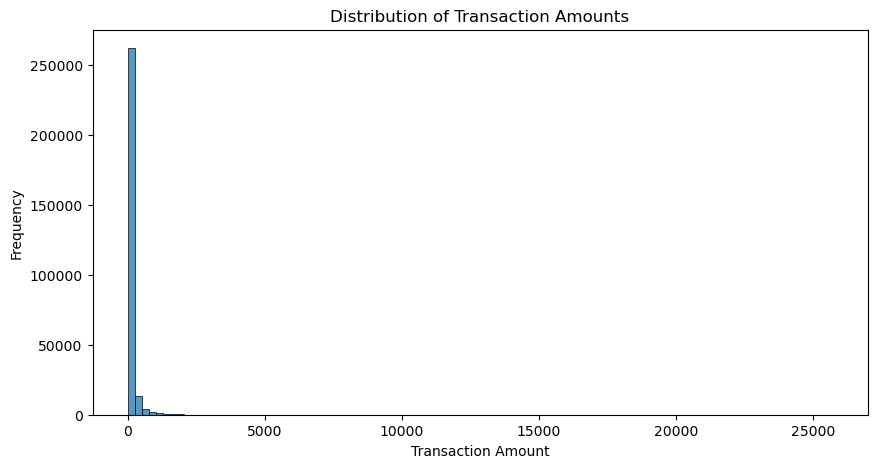

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Amount", bins=100)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.show()

### 4.1 Amount distribution: severe right skew

The ``Amount`` histogram shows a strong **right-skewed distribution**, meaning most transactions have smaller amounts, while a small number have much higher amounts. The median is **22.00**, the mean is **88.47**, and the highest transaction amount is **25,691.16.** The mean is much higher than the median because a few high-value transactions increase the overall average.

**Interpretation:** The mean alone does not accurately represent a typical transaction amount. A normal histogram may make it difficult to see smaller transaction amounts clearly because of the very high values. Therefore, a ``log1p(Amount)`` plot is used to make smaller values easier to compare. The ``log1p`` transformation can also handle zero values safely. In the existing notebook, it is only used for visualisation and not as an additional feature for prediction.

**Modelling implication:** Feature scaling can improve the performance of linear models, especially those that use regularisation. However, tree-based models are generally less affected by differences in feature scales. Extremely high transaction amounts should not be removed automatically, as they may contain useful information for identifying fraudulent transactions.


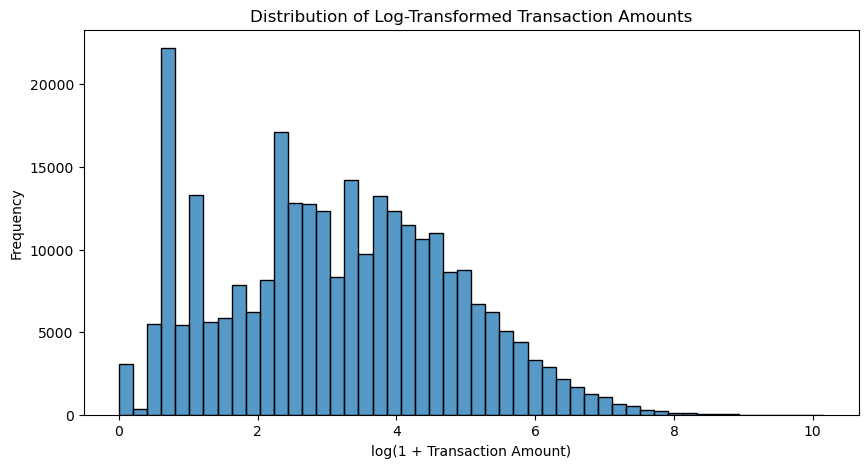

In [14]:

plt.figure(figsize=(10, 5))

sns.histplot(
    x=np.log1p(df["Amount"]),
    bins=50
)

plt.title("Distribution of Log-Transformed Transaction Amounts")
plt.xlabel("log(1 + Transaction Amount)")
plt.ylabel("Frequency")
plt.show()


### 4.2 Why log-scale analysis matters

The log transform spreads lower monetary values and compresses the extreme right tail, exposing the shape of the **common** transaction range. This does not mean a log-transformed distribution becomes normal or that fraud and legitimate transactions are separable using amount alone. A valid comparison needs class-specific plots and rates, shown next.


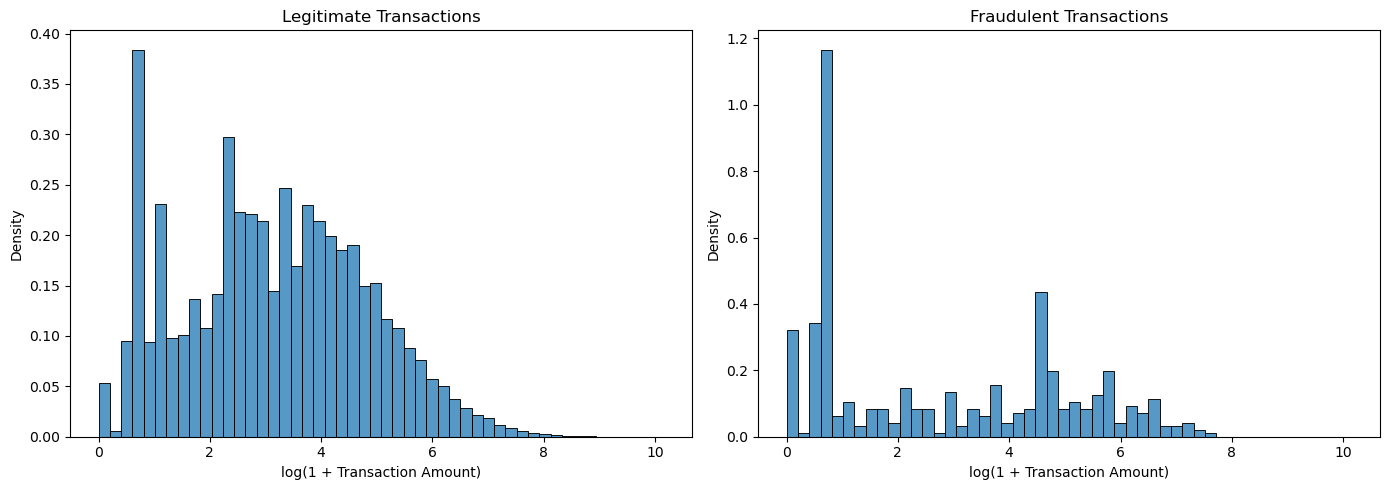

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=False)

for i, ax in enumerate(axes):
    sns.histplot(
        np.log1p(df[df["Class"] == i]["Amount"]),
        bins=np.linspace(0, np.log1p(df["Amount"].max()), 51),
        stat="density",
        ax=ax
    )
    ax.set_title("Legitimate Transactions" if i == 0 else "Fraudulent Transactions")
    ax.set_xlabel("log(1 + Transaction Amount)")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

### 4.3 Fraud vs. legitimate amount distributions

The side-by-side histograms compare the transaction amount distributions for legitimate and fraudulent transactions. Since there are many more legitimate transactions than fraudulent ones, their total bar counts cannot be compared directly. Instead, the focus should be on the overall shapes of the distributions. Later fraud-rate graphs can provide a clearer comparison of the likelihood of fraud at different transaction amounts.

The next boxplot hides extreme values (``showfliers=False``) to make the graph easier to read. However, these extreme values are still included in the dataset and have not been removed.


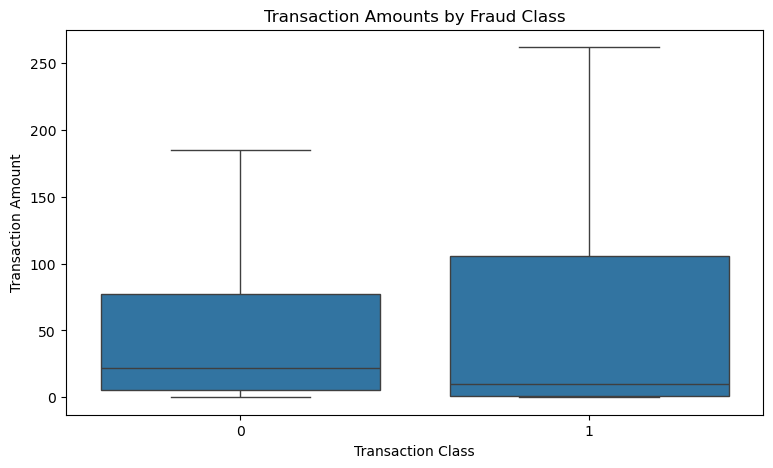

In [16]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount",
    showfliers=False
)

plt.title("Transaction Amounts by Fraud Class")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.show()

In [17]:
df.groupby("Class")["Amount"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
Class,,,,,,
0,283253,88.413575,22.00,250.379023,0.0,25691.16
1,473,123.871860,9.82,260.211041,0.0,2125.87


**Group-level interpretation:** Fraudulent transactions have a **higher mean** amount (**123.87** vs. **88.41**) but a **lower median** (**9.82** vs. **22.00**) than legitimate transactions. This is because fraudulent transactions include many low-value transactions as well as a small number of high-value transactions that increase the average. Therefore, it would be incorrect to conclude that fraudulent transactions are generally larger.

The transaction amount may help identify fraudulent activity, but it is not enough on its own to classify fraud accurately. The anonymous ``V`` features also provide useful information that can help the model distinguish between legitimate and fraudulent transactions.

In [18]:
Q1 = df["Amount"].quantile(0.25)
Q3 = df["Amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["Amount"] < lower_bound) |
    (df["Amount"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))
print("Percentage:", len(outliers) / len(df) * 100)

Lower bound: -102.26500000000001
Upper bound: 185.375
Number of outliers: 31685
Percentage: 11.1674643846528


In [19]:
df["Amount_Outlier"] = (
    (df["Amount"] < lower_bound) |
    (df["Amount"] > upper_bound)
)

print(
    df.groupby("Amount_Outlier")["Class"]
      .agg(["count", "sum", "mean"])
)

                 count  sum      mean
Amount_Outlier                       
False           252041  386  0.001531
True             31685   87  0.002746


### 4.4 Outliers and fraud enrichment

The IQR rule flags amounts above **185.375** (the mathematical lower bound is negative, so no non-negative amounts fall below it). It marks **31,685 / 283,726 = 11.17%** of records as amount outliers.

| Group | Fraud / total | Fraud rate |
|---|---:|---:|
| Not amount outlier | 386 / 252,041 | **0.1531%** |
| Amount outlier | 87 / 31,685 | **0.2746%** |

The fraud rate among high-amount outliers is approximately **1.79 times higher** than among transactions that are not outliers. However, **386 out of 473 fraudulent transactions (81.6%) are not identified as outliers**. This means that relying only on unusually high transaction amounts to detect fraud would miss most fraudulent transactions.

Therefore, outliers should not be removed automatically, as they may contain important information that helps identify fraud.

The ``Amount_Outlier`` feature is only used for descriptive analysis in this study. Since its cut-off value was calculated using the entire dataset, the limits should be calculated using training data only if this feature is later used for prediction. This helps prevent data leakage.

In [20]:
df["Time"].describe()

count    283726.000000
mean      94811.077600
std       47481.047891
min           0.000000
25%       54204.750000
50%       84692.500000
75%      139298.000000
max      172792.000000
Name: Time, dtype: float64

### 4.5 Time-variable interpretation

`Time` ranges from **0 to 172,792 seconds**, roughly **48 hours** after the first recorded transaction. The mean (**94,811 seconds**) should be interpreted as position within the collection window, **not** local clock time. The plot that follows compares class-specific temporal distributions.

Because the variable is elapsed time and spans about two days, it cannot independently identify weekends, business hours, or exact circadian patterns; stronger time-of-day claims require timestamps/time-zone metadata.


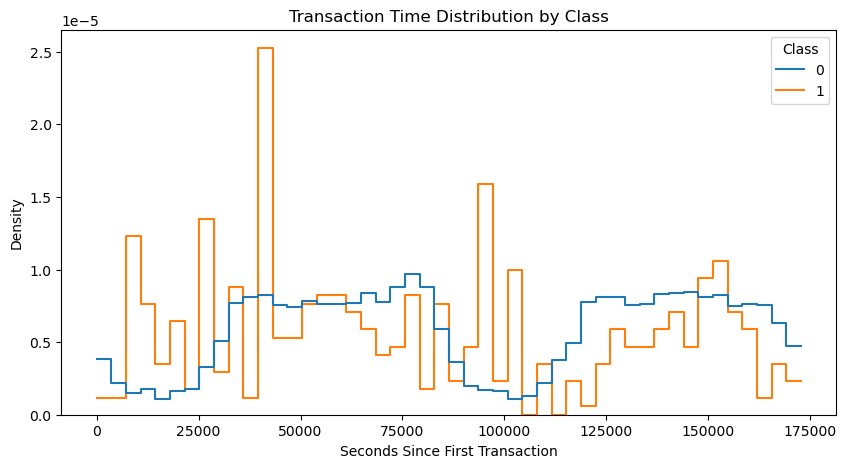

In [21]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Time",
    hue="Class",
    bins=48,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.title("Transaction Time Distribution by Class")
plt.xlabel("Seconds Since First Transaction")
plt.ylabel("Density")
plt.show()

**Plot-reading note:** `stat='density'` and `common_norm=False` allow each group (fraudulent and legitimate transactions) to be displayed separately based on its own distribution. Therefore, the curves compare the patterns of transaction times rather than the actual number of fraudulent and legitimate transactions. The next hourly fraud-rate graph shows something different: the percentage of transactions that are fraudulent during each hour.

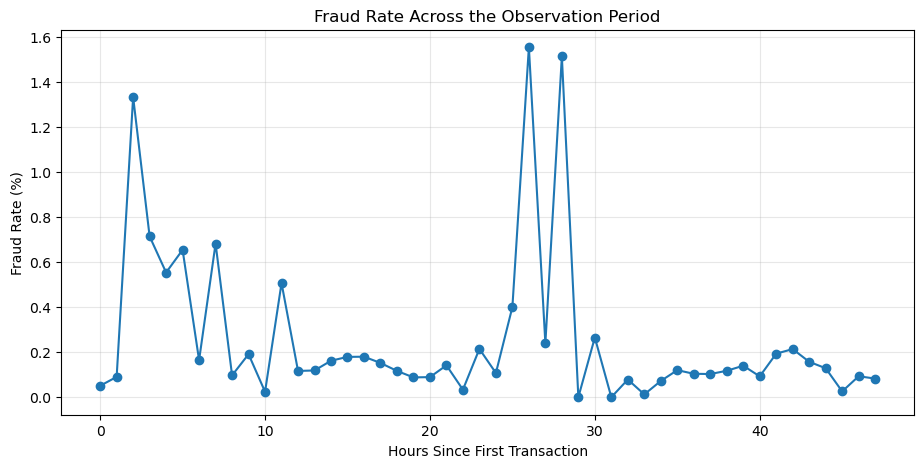

In [22]:
# Group elapsed time into one-hour intervals
df["HourBin"] = (df["Time"] // 3600).astype(int)

# Average of a binary column = proportion of 1s
hourly_fraud_rate = (
    df.groupby("HourBin")["Class"].mean() * 100
)

plt.figure(figsize=(11, 5))

hourly_fraud_rate.plot(kind="line", marker="o")

plt.title("Fraud Rate Across the Observation Period")
plt.xlabel("Hours Since First Transaction")
plt.ylabel("Fraud Rate (%)")
plt.grid(alpha=0.3)
plt.show()

**Hourly-rate interpretation:** `HourBin = Time // 3600` groups the approximately 48-hour observation window into elapsed-hour intervals. Each point shows **fraud count divided by all transactions in that interval**, expressed as a percentage. However, some peaks may be caused by only a small number of fraudulent transactions, especially during hours with fewer transactions. Since the graph does not show the total number of transactions or the level of uncertainty for each hour, these peaks should not be treated as strong evidence of fraud patterns.

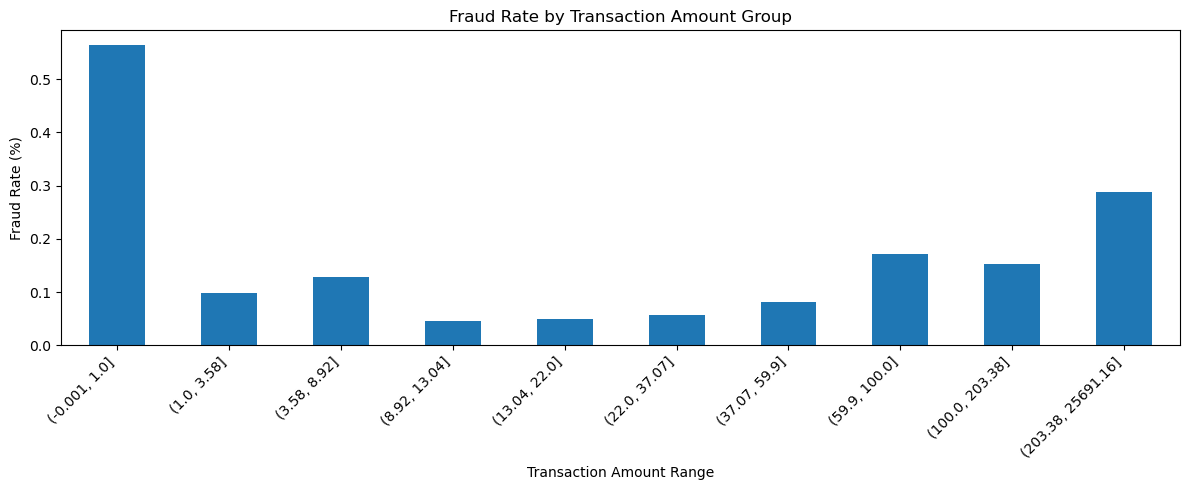

In [23]:
# Split amounts into quantile-based groups
amount_bins = pd.qcut(
    df["Amount"],
    q=10,
    duplicates="drop"
)

# Fraud rate for each amount group
fraud_by_amount = (
    df.groupby(amount_bins, observed=True)["Class"]
      .mean() * 100
)

fraud_by_amount.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Fraud Rate by Transaction Amount Group")
plt.xlabel("Transaction Amount Range")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 4.6 Fraud frequency by amount bin

The quantile bins group transactions into intervals that contain roughly the same number of transactions, rather than dividing them into equal ranges of transaction amounts. The bar heights show the **fraud rate within each amount range**, not the percentage of all fraudulent transactions found in that range. These rates can be compared with the overall fraud rate of **0.1667%** to identify amount ranges that may have a higher chance of fraud. However, small differences in the graph should not be treated as confirmed patterns without checking the transaction counts or confidence intervals.

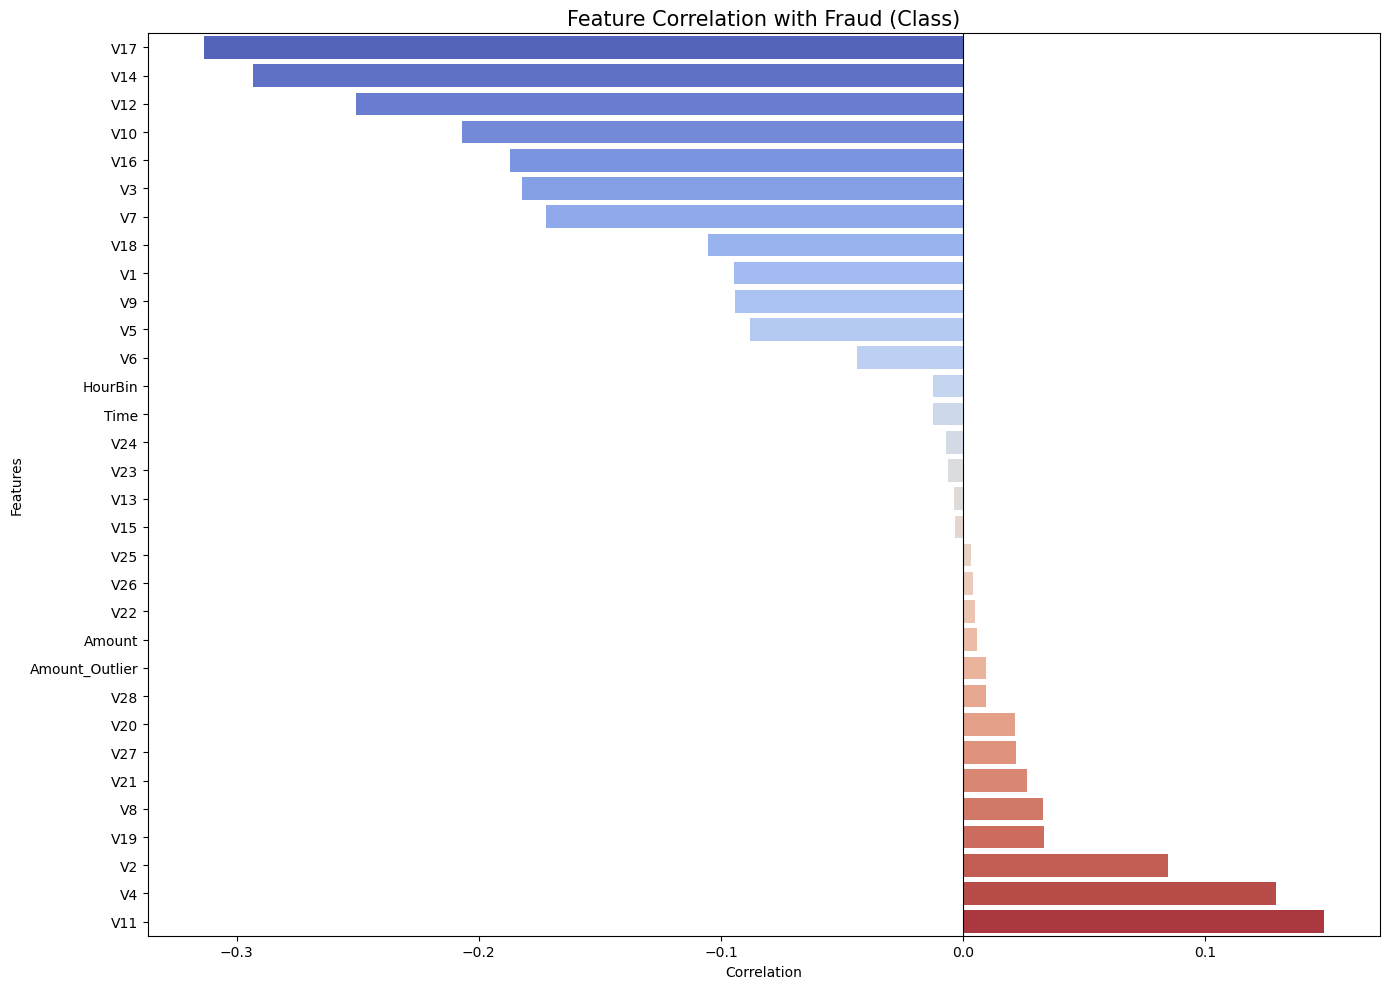

In [24]:
# correlation with target variable 
class_corr = df.corr(numeric_only=True)["Class"].drop("Class")

# sort correlation values
class_corr = class_corr.sort_values() 

plt.figure(figsize=(14, 10))
sns.barplot(
    x = class_corr.values,
    y = class_corr.index,
    hue=class_corr.index,
    palette="coolwarm",
    legend=False
)

plt.title("Feature Correlation with Fraud (Class)",fontsize=15)
plt.xlabel("Correlation")
plt.ylabel("Features")
plt.axvline(x=0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

### 4.7 Correlations: association, not feature importance

This plot ranks each numeric variable by its **Pearson correlation** with binary `Class`. Negative bars mean higher feature values tend to associate with the legitimate class and lower values with fraud, *in a linear sense*. Positive bars indicate the reverse.

Cautions: (i) PCA coordinates `V1`–`V28` do not have meaningful human-readable semantics; (ii) low marginal correlation **does not imply that a feature is useless**, because fraud signals can be nonlinear or interactive; (iii) correlational associations do not establish a causal mechanism. The EDA helper variables `HourBin` and `Amount_Outlier` are included in the computed `df.corr` at this point, but **not included in model features**.


In [25]:
# correlation matrix
df.corr(numeric_only=True)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V23,V24,V25,V26,V27,V28,Amount,Class,Amount_Outlier,HourBin
Time,1.000000,0.117927,-0.010556,-0.422054,-0.105845,0.173223,-0.063279,0.085335,-0.038203,-0.007861,...,0.051474,-0.015954,-0.233262,-0.041818,-0.005171,-0.009305,-0.010559,-0.012359,-0.010420,0.999757
V1,0.117927,1.000000,0.006875,-0.008112,0.002257,-0.007036,0.000413,-0.009173,-0.001168,0.001828,...,-0.001330,-0.000723,-0.000222,-0.000684,-0.015706,-0.004861,-0.230105,-0.094486,-0.137932,0.118196
V2,-0.010556,0.006875,1.000000,0.005278,-0.001495,0.005210,-0.000594,0.007425,0.002899,-0.000274,...,-0.003855,0.000701,-0.001569,0.000253,0.007555,0.001611,-0.533428,0.084624,-0.394294,-0.010592
V3,-0.422054,-0.008112,0.005278,1.000000,0.002829,-0.006879,-0.001511,-0.011721,-0.001815,-0.003579,...,0.000449,-0.000072,0.000425,-0.000094,-0.007051,-0.000134,-0.212410,-0.182322,-0.113567,-0.422045
V4,-0.105845,0.002257,-0.001495,0.002829,1.000000,0.001744,-0.000880,0.004657,0.000890,0.002154,...,0.000732,-0.000120,0.000162,0.000777,0.001322,0.000231,0.099514,0.129326,0.037997,-0.105827
V5,0.173223,-0.007036,0.005210,-0.006879,0.001744,1.000000,-0.000938,-0.008709,0.001430,-0.001213,...,0.001183,0.000198,0.000069,0.000390,-0.005798,-0.000820,-0.387685,-0.087812,-0.238641,0.173358
V6,-0.063279,0.000413,-0.000594,-0.001511,-0.000880,-0.000938,1.000000,0.000436,0.003036,-0.000734,...,-0.000755,0.001202,0.000697,-0.000028,0.000289,0.000925,0.216389,-0.043915,0.125553,-0.063247
V7,0.085335,-0.009173,0.007425,-0.011721,0.004657,-0.008709,0.000436,1.000000,-0.006419,-0.004921,...,0.003303,-0.000384,-0.000072,0.000624,-0.004537,0.001657,0.400408,-0.172347,0.192263,0.085360
V8,-0.038203,-0.001168,0.002899,-0.001815,0.000890,0.001430,0.003036,-0.006419,1.000000,0.001038,...,0.004994,0.000113,0.000011,-0.001407,0.000613,-0.000099,-0.104662,0.033068,-0.059567,-0.038309
V9,-0.007861,0.001828,-0.000274,-0.003579,0.002154,-0.001213,-0.000734,-0.004921,0.001038,1.000000,...,0.000677,-0.000103,-0.000275,0.001253,0.008221,0.005591,-0.044123,-0.094021,-0.021795,-0.007258


**EDA synthesis:** The data exhibit severe target imbalance, a highly skewed amount distribution, fraud-enriched high-amount outliers with limited standalone sensitivity, and potential signal in anonymised components. The appropriate modelling question is not 'Can we achieve high accuracy?' but 'Can we find a useful fraud-recall/false-alert balance on unseen transactions?'

**Further EDA (not yet implemented):** A fraud-rate plot with counts/confidence intervals, per-class distributions for the most associated PCA coordinates, and a training-only check of predictive signal stability would strengthen the analysis.


## 5. Data Preprocessing, Splits, and Imbalance Handling

**Feature set:** Only the 30 original predictors (`Time`, `Amount`, `V1`–`V28`) are used. The EDA-only variables `HourBin` and `Amount_Outlier` are **explicitly excluded**, avoiding accidental reuse of exploratory helper columns as predictive features.

**Split strategy:** A stratified split creates 60% training (**170,235 rows**), 20% validation (**56,745 rows**), and 20% test (**56,746 rows**). Stratification helps preserve the rare fraud rate across splits. The validation set supports model comparison and threshold selection; the held-out test set estimates generalisation.

**Preprocessing:** ``StandardScaler`` is fitted using **training data only** before being applied to the validation and test data. This prevents information from the validation and test sets from affecting the scaling process. ``RandomUnderSampler(sampling_strategy=0.05)`` is applied **only to the scaled training data** used by Logistic Regression and Random Forest. This reduces the training data to **5,680 legitimate transactions and 284 fraudulent transactions.** The ratio of 0.05 means there are 5 fraudulent transactions for every 100 legitimate transactions. It does not represent a 5% fraud rate in the original dataset.

**Comparison caution:** XGBoost trains on the **full, unscaled training set** with `scale_pos_weight=10`, whereas Logistic Regression and Random Forest train on the undersampled set. Therefore, the results compare the overall modelling processes, rather than comparing only the model types under the same training conditions.

In [26]:
# Original 30 features only
features = ["Time", "Amount"] + [f"V{i}" for i in range(1, 29)]

X = df[features].copy()
y = df["Class"].copy()

In [27]:
from sklearn.model_selection import train_test_split

# First split: 80% training + validation, 20% testing
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: 60% training, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,
    test_size=0.25,
    random_state=42,
    stratify=y_trainval
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (170235, 30)
Validation: (56745, 30)
Testing: (56746, 30)


**Split sizes and anti-leakage checkpoint:** Because both splits use `stratify`, approximately 60/20/20 of each class is allocated to training/validation/test. The saved validation sample contains **94 fraud transactions** and the test sample **95**. These numbers are relatively small, meaning that even a few incorrect predictions can significantly affect the model's precision and recall scores.

**Future robustness concern:** A random split of transactions does not show how well the model performs on newer transactions that occur later. Using a chronological split, where older transactions are used for training and newer transactions are used for testing, would provide a better way to evaluate the model's performance over time. However, this approach may be limited by the dataset's short two-day observation period and the way its ``Time`` feature is recorded.

In [28]:
from sklearn.preprocessing import StandardScaler 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

**Why scaling is correctly ordered:** `fit_transform(X_train)` learns the standardisation parameters using only training data; `transform` then reuses them for the validation and test sets. This is an appropriate leakage barrier for Logistic Regression. XGBoost later receives unscaled data, which is acceptable for tree methods.


In [29]:
# Handling imbalance 

from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state = 42, sampling_strategy=0.05)
X_train_balanced, y_train_balanced = rus.fit_resample(
    X_train_scaled, 
    y_train
)


In [30]:
y_train_balanced.value_counts()

Class
0    5680
1     284
Name: count, dtype: int64

**What undersampling changes:** The training data are reduced from **170,235** to **5,964** observations, while retaining all **284 training fraud cases** and selecting **5,680 legitimate cases**. This helps the model focus more on fraudulent transactions, which are much less common. However, it also removes a large amount of information about the different patterns of legitimate transactions. In addition, it changes the balance between fraudulent and legitimate transactions in the training data. As a result, the model's predicted fraud probabilities may not accurately reflect the actual fraud rate in real-world transactions.

**Methodological choice:** Models should be evaluated using the **original validation data without removing any transactions**, as done in the notebook. Other approaches, such as applying class weights or comparing different sampling methods, should also be considered before deciding that undersampling is the best approach. SMOTE does not always improve model performance, especially when using anonymous PCA features and a dataset with very few fraudulent transactions.

In [31]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_balanced, y_train_balanced)

y_val_pred = model.predict(X_val_scaled)
y_val_prob = model.predict_proba(X_val_scaled)[:, 1]

## 6. Model 1 — Logistic Regression Baseline

Logistic Regression provides a simple starting point for checking whether the anonymous features can help distinguish between legitimate and fraudulent transactions. It uses a weighted combination of input features to make predictions. However, because it uses a linear decision boundary, it may not perform as well when fraud patterns are more complex.

This experiment uses scaled and undersampled training data, with `max_iter=1000` and the default prediction threshold of **0.50**. Its main purpose is to provide a consistent **baseline for comparison with more advanced models**, such as Random Forest and XGBoost.

In [32]:
from sklearn.metrics import confusion_matrix 

cm = confusion_matrix(y_val, y_val_pred)
print(cm)

[[56559    92]
 [   10    84]]


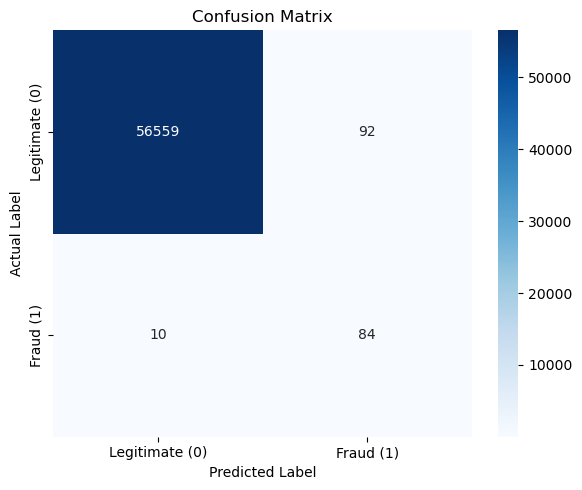

In [33]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate (0)", "Fraud (1)"],
    yticklabels=["Legitimate (0)", "Fraud (1)"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

print("Accuracy:", accuracy_score(y_val, y_val_pred))
print("Precision:", precision_score(y_val, y_val_pred))
print("Recall:", recall_score(y_val, y_val_pred))
print("F1 Score:", f1_score(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

Accuracy: 0.998202484800423
Precision: 0.4772727272727273
Recall: 0.8936170212765957
F1 Score: 0.6222222222222222

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.48      0.89      0.62        94

    accuracy                           1.00     56745
   macro avg       0.74      0.95      0.81     56745
weighted avg       1.00      1.00      1.00     56745



Logistic Regression
ROC-AUC: 0.9796
Average Precision: 0.7917


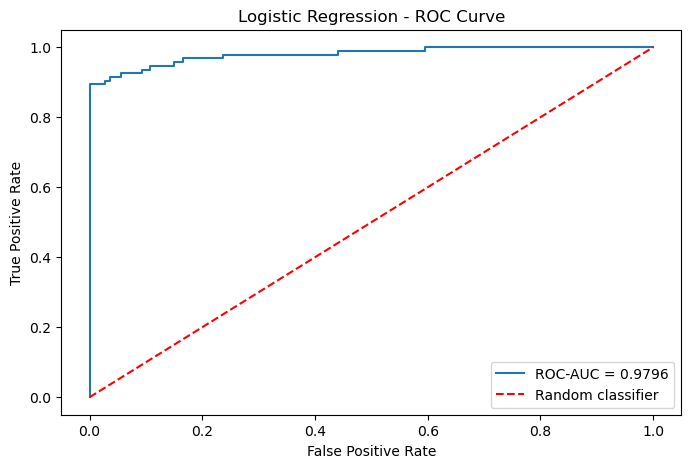

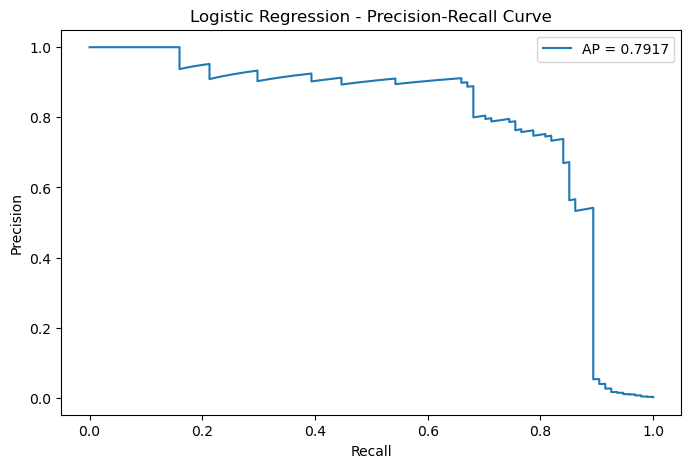

In [35]:

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    average_precision_score,
    precision_recall_curve
)

# ROC-AUC using predicted probabilities
roc_auc = roc_auc_score(y_val, y_val_prob)

# Average Precision (AP)
pr_auc = average_precision_score(y_val, y_val_prob)

print("Logistic Regression")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"Average Precision: {pr_auc:.4f}")

# ROC Curve
fpr, tpr, roc_thresholds = roc_curve(y_val, y_val_prob)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1], "r--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression - ROC Curve")
plt.legend()
plt.show()

# Precision-Recall Curve
precision, recall, pr_thresholds = precision_recall_curve(
    y_val, y_val_prob
)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision, label=f"AP = {pr_auc:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Logistic Regression - Precision-Recall Curve")
plt.legend()
plt.show()


### 6.1 Logistic Regression: results and error profile

On **56,745 validation transactions**, the confusion matrix is **[[56,559, 92], [10, 84]]**. Thus the baseline correctly detects **84/94 frauds** (recall **89.36%**) but also wrongly flags **92 legitimate payments**, leading to relatively low fraud precision (**47.73%**) and F1 (**62.22%**).

Its **ROC-AUC 0.9796** indicates strong ranking discrimination, and **AP 0.7917** is far above the prevalence-only reference of approximately **0.00166**. However, a good ROC-AUC does not guarantee few false alerts at the chosen threshold. Precision–recall curves should therefore receive more attention than accuracy here.


## 7. Model 2 — Random Forest

**Method:** Random Forest combines multiple decision trees to make predictions. Each tree is trained using a different sample of the training data and considers different features. This allows the model to identify more complex patterns and relationships between features without needing to define them manually.

**Training choice:** Random Forest uses the same scaled and undersampled training data as Logistic Regression. Although scaling is not usually necessary for tree-based models, using scaled data does not negatively affect the validity of the comparison. The model uses the default library settings, except for ``random_state=42``. No hyperparameter tuning is performed in this section.

**Hypothesis:** Random Forest may perform better than Logistic Regression because it can identify more complex fraud patterns. It may also reduce false positives while maintaining a high fraud detection rate.


In [36]:
from sklearn.ensemble import RandomForestClassifier

model_v2 = RandomForestClassifier(random_state = 42)
model_v2.fit(X_train_balanced, y_train_balanced)

y_val_pred_2 = model_v2.predict(X_val_scaled)
y_val_prob_2 = model_v2.predict_proba(X_val_scaled)[:, 1]

In [37]:
cm_2 = confusion_matrix(y_val, y_val_pred_2)
print(cm_2) 

[[56607    44]
 [   11    83]]


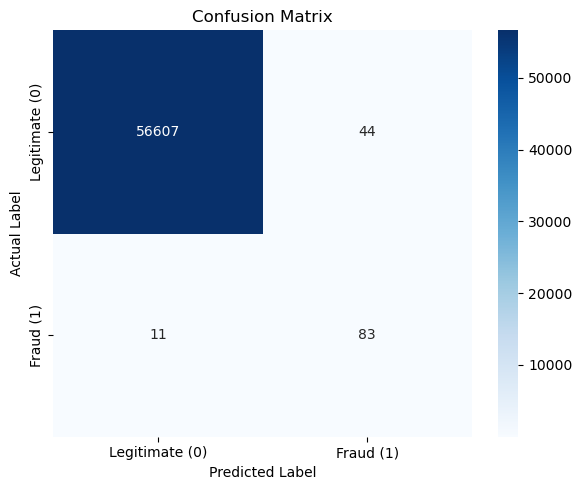

In [38]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_2,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate (0)", "Fraud (1)"],
    yticklabels=["Legitimate (0)", "Fraud (1)"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [39]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

print("Accuracy:", accuracy_score(y_val, y_val_pred_2))
print("Precision:", precision_score(y_val, y_val_pred_2))
print("Recall:", recall_score(y_val, y_val_pred_2))
print("F1 Score:", f1_score(y_val, y_val_pred_2))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_2))

Accuracy: 0.9990307516080712
Precision: 0.6535433070866141
Recall: 0.8829787234042553
F1 Score: 0.751131221719457

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.65      0.88      0.75        94

    accuracy                           1.00     56745
   macro avg       0.83      0.94      0.88     56745
weighted avg       1.00      1.00      1.00     56745



Random Forest
ROC-AUC: 0.9591
Average Precision: 0.8363


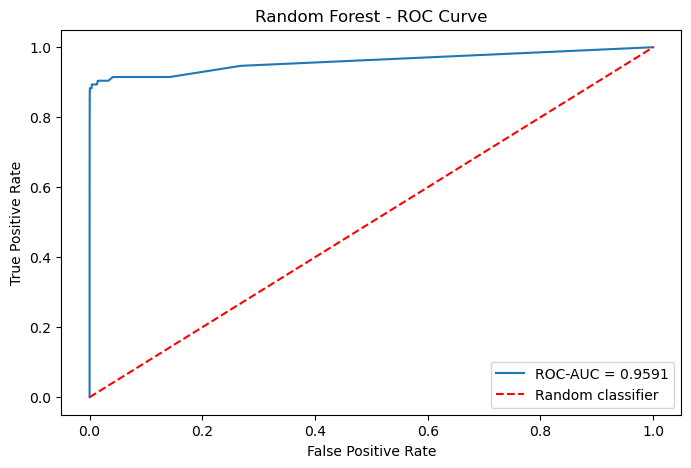

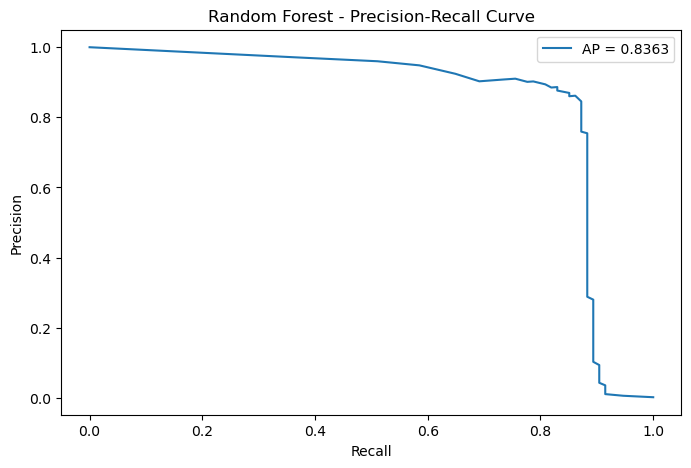

In [40]:
# Random Forest ROC-AUC and Average Precision
roc_auc_2 = roc_auc_score(y_val, y_val_prob_2)
pr_auc_2 = average_precision_score(y_val, y_val_prob_2)

print("Random Forest")
print(f"ROC-AUC: {roc_auc_2:.4f}")
print(f"Average Precision: {pr_auc_2:.4f}")

# ROC Curve
fpr_2, tpr_2, roc_thresholds_2 = roc_curve(
    y_val, y_val_prob_2
)

plt.figure(figsize=(8, 5))
plt.plot(fpr_2, tpr_2, label=f"ROC-AUC = {roc_auc_2:.4f}")
plt.plot([0, 1], [0, 1], "r--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest - ROC Curve")
plt.legend()
plt.show()

# Precision-Recall Curve
precision_2, recall_2, pr_thresholds_2 = precision_recall_curve(
    y_val, y_val_prob_2
)

plt.figure(figsize=(8, 5))
plt.plot(recall_2, precision_2, label=f"AP = {pr_auc_2:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest - Precision-Recall Curve")
plt.legend()
plt.show()


### 7.1 Random Forest: results and comparison

Validation confusion matrix: **[[56,607, 44], [11, 83]]**. The forest detects **83/94 frauds** (recall **88.30%**) and yields **44 false positives**, reducing false alerts by **48** versus Logistic Regression at their default thresholds. Precision rises from **47.73% to 65.35%**, and F1 rises from **62.22% to 75.11%**.

**AP increases from 0.7917 to 0.8363**, even though ROC-AUC decreases from **0.9796 to 0.9591**. This happens because the two metrics measure model performance differently. AP focuses more on how well the model identifies fraudulent transactions, which is especially useful when fraud cases are rare. No statistical significance is claimed because the results are based on a single data split.


## 8. Model 3 — XGBoost Gradient-Boosted Trees

**Method:** XGBoost builds multiple decision trees one after another, with each new tree focusing on correcting the errors made by the previous trees. This allows the model to identify complex patterns and relationships between features that may help detect fraudulent transactions.

**Specified configuration:** `n_estimators=400`, `max_depth=4`, `learning_rate=0.05`, `subsample=0.8`, `colsample_bytree=0.8`, `min_child_weight=3`, `reg_lambda=5`, `scale_pos_weight=10`, and `eval_metric='aucpr'`.

**Important distinction:** These settings were manually chosen in the notebook. They do not mean that a grid search, random search or Bayesian optimisation was performed to find the best settings. The original class ratio is **598.42:1**, but the model uses ``scale_pos_weight=10`` instead of the full inverse class ratio. This is a deliberate choice that may help improve precision compared to using a much higher weight for fraud cases. However, this has not been confirmed through a controlled comparison.

Unlike Logistic Regression and Random Forest, XGBoost is trained using the **original training data without undersampling**. This allows it to retain all legitimate and fraudulent transactions. The model produces a probability score for each transaction, and the default threshold of **0.50** is used to classify transactions as either fraudulent or legitimate.


In [41]:
%pip install -q xgboost

Note: you may need to restart the kernel to use updated packages.


In [42]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

In [43]:
# Calculate class imbalance
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()

imbalance_ratio = neg / pos

print(f"Legitimate transactions: {neg}")
print(f"Fraudulent transactions: {pos}")
print(f"Imbalance ratio: {imbalance_ratio:.2f}")

# Initialize XGBoost
model_v3 = XGBClassifier(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=5,
    scale_pos_weight=10,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Train on original training data, NOT undersampled data
model_v3.fit(X_train, y_train)

Legitimate transactions: 169951
Fraudulent transactions: 284
Imbalance ratio: 598.42


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'aucpr'


In [44]:
# Predict on validation data
y_val_pred_3 = model_v3.predict(X_val)

# Predicted probability of fraud
y_val_prob_3 = model_v3.predict_proba(X_val)[:, 1]

In [45]:
print("Accuracy:", accuracy_score(y_val, y_val_pred_3))
print("Precision:", precision_score(y_val, y_val_pred_3))
print("Recall:", recall_score(y_val, y_val_pred_3))
print("F1 Score:", f1_score(y_val, y_val_pred_3))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_3))

Accuracy: 0.9996123006432285
Precision: 0.9090909090909091
Recall: 0.851063829787234
F1 Score: 0.8791208791208791

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.91      0.85      0.88        94

    accuracy                           1.00     56745
   macro avg       0.95      0.93      0.94     56745
weighted avg       1.00      1.00      1.00     56745



### 8.1 XGBoost: default-threshold classification

On the **validation set at threshold 0.50**, XGBoost achieves **90.91% precision**, **85.11% recall**, and **87.91% F1**. The positive-class support is **94**, so this corresponds to **80 true positives, 14 false negatives, and 8 false positives** (implied confusion matrix **[[56,643, 8], [14, 80]]**).

Compared with the Random Forest, XGBoost reduces false alerts from **44 to 8** but misses **3 more frauds** (14 rather than 11). This means XGBoost is more effective at reducing false alerts, but it also fails to detect slightly more fraud cases. Whether this is a better result depends on the importance of detecting every possible fraud case compared to avoiding unnecessary alerts and reviews.

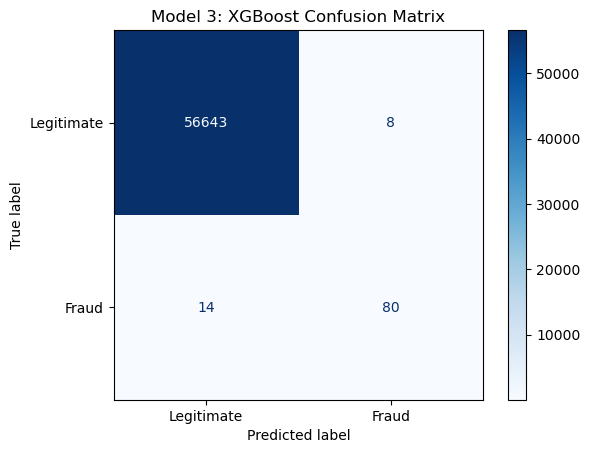

In [46]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_3,
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",
    values_format="d"
)

plt.title("Model 3: XGBoost Confusion Matrix")
plt.show()

In [47]:
roc_auc_3 = roc_auc_score(y_val, y_val_prob_3)
pr_auc_3 = average_precision_score(y_val, y_val_prob_3)

print(f"ROC-AUC: {roc_auc_3:.4f}")
print(f"Average Precision (AP): {pr_auc_3:.4f}")

ROC-AUC: 0.9805
Average Precision (AP): 0.8881


### 8.2 Ranking metrics for XGBoost

At validation time, XGBoost achieves **ROC-AUC 0.9805** and **average precision (AP) 0.8881**, the best AP among the three saved experiments (**Logistic Regression 0.7917; Random Forest 0.8363; XGBoost 0.8881**). Average Precision measures how well the model identifies fraudulent transactions across different prediction thresholds by considering both precision and recall. Unlike precision, recall and F1-score, which depend on a specific threshold, AP considers performance across multiple thresholds.

It is important to use the term Average Precision (AP) rather than simply calling it PR-AUC, as the two measurements are not always calculated in exactly the same way.

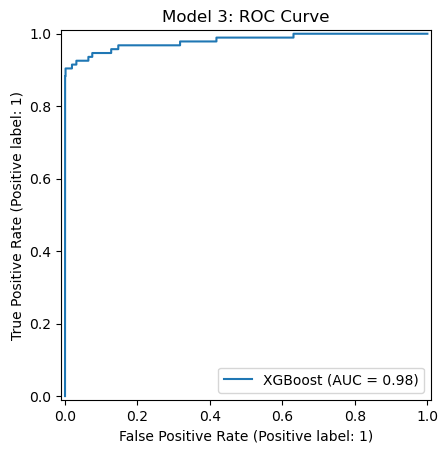

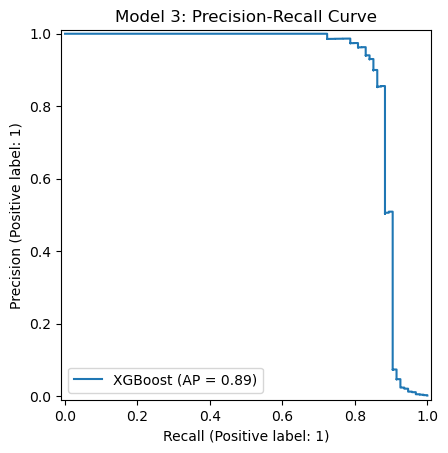

In [48]:
RocCurveDisplay.from_predictions(
    y_val,
    y_val_prob_3,
    name="XGBoost"
)

plt.title("Model 3: ROC Curve")
plt.show()


PrecisionRecallDisplay.from_predictions(
    y_val,
    y_val_prob_3,
    name="XGBoost"
)

plt.title("Model 3: Precision-Recall Curve")
plt.show()

## 8.3 Consolidated Model Comparison — Validation Set

The results below are derived from the saved notebook outputs (default prediction threshold **0.50**):

| Model | Precision | Recall | F1 | ROC-AUC | Average precision | False positives | Missed fraud |
|---|---:|---:|---:|---:|---:|---:|---:|
| Logistic Regression + undersampling | 47.73% | **89.36%** | 62.22% | 0.9796 | 0.7917 | 92 | 10 |
| Random Forest + undersampling | 65.35% | 88.30% | 75.11% | 0.9591 | 0.8363 | 44 | 11 |
| XGBoost + class weighting | **90.91%** | 85.11% | **87.91%** | **0.9805** | **0.8881** | **8** | 14 |

**Conclusion:** XGBoost has the strongest **validation precision, F1, and AP** in these experiments; Logistic Regression has the highest **default-threshold validation recall**. These gains cannot be attributed to XGBoost architecture alone, because the pipelines use different training distributions and settings. For the remainder of the notebook, XGBoost is evaluated using the **unchanged 0.50 decision threshold**, keeping the validation and test comparisons consistent.


## 9. Held-Out Test Evaluation — XGBoost at Threshold 0.50

**Test evaluation:** The previously trained XGBoost model is tested using the separate 20% test dataset with a fixed prediction threshold of **0.50**. This threshold was not adjusted or optimised during the final testing stage.

| Test metric | Value | Meaning |
|---|---:|---|
| Precision (fraud) | **94.81%** | About 95 of every 100 flagged transactions are fraud within this historical test set |
| Recall (fraud) | **76.84%** | Roughly 77 of every 100 fraudulent transactions are detected |
| F1 | **84.88%** | Measures the balance between precision and recall |
| ROC-AUC | **0.9722** | Measures how well the model separates fraud from legitimate transactions |
| Average precision (AP) | **0.8345** | Measures how well the model identifies fraud across different thresholds |
| Accuracy | **99.95%** | Shows the percentage of all transactions correctly classified, but can be misleading because legitimate transactions are much more common |

Based on 95 fraud transactions in the test set, recall of 76.84% corresponds to **73 detected frauds and 22 missed frauds**. Precision of 94.81% corresponds to **4 false alarms** alongside 73 true positives. Thus, the implied confusion matrix (actual rows 0/1, predicted columns 0/1) is **[[56,647, 4], [22, 73]]**.

**Operational interpretation:** The model uses a relatively conservative prediction threshold. This means it produces very few false alerts but also misses more than one-fifth of fraudulent transactions. Since the dataset does not include information about financial losses from fraud or the cost of reviewing suspicious transactions, we cannot conclude that the 0.50 threshold is the most financially suitable choice.

In [49]:
final_model = model_v3
model_name = "XGBoost"
X_final_test = X_test

In [50]:
# Generate test predictions
y_test_prob = final_model.predict_proba(X_final_test)[:, 1]

# Use the threshold chosen during validation
final_threshold = 0.5  # Change only if validation selected another threshold
y_test_pred = (y_test_prob >= final_threshold).astype(int)

# Calculate metrics
test_results = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test, y_test_pred),
    "F1 Score": f1_score(y_test, y_test_pred),
    "ROC-AUC": roc_auc_score(y_test, y_test_prob),
    "Average Precision": average_precision_score(y_test, y_test_prob)
}

print(f"FINAL TEST RESULTS — {model_name}")
print("-" * 40)

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Legitimate", "Fraud"]
))

FINAL TEST RESULTS — XGBoost
----------------------------------------
Accuracy: 0.9995
Precision: 0.9481
Recall: 0.7684
F1 Score: 0.8488
ROC-AUC: 0.9722
Average Precision: 0.8345

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.95      0.77      0.85        95

    accuracy                           1.00     56746
   macro avg       0.97      0.88      0.92     56746
weighted avg       1.00      1.00      1.00     56746



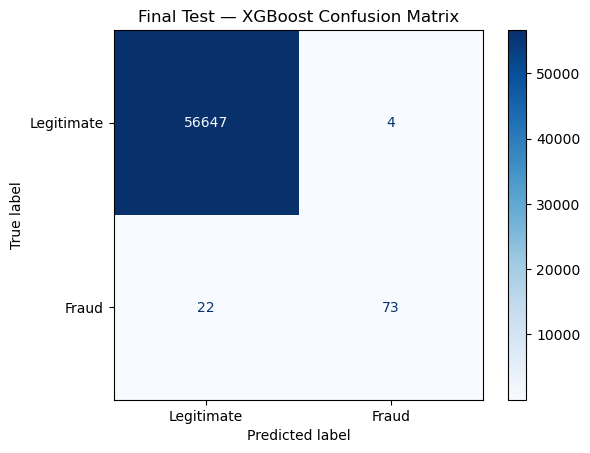

In [51]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",
    values_format="d"
)

plt.title(f"Final Test — {model_name} Confusion Matrix")
plt.show()

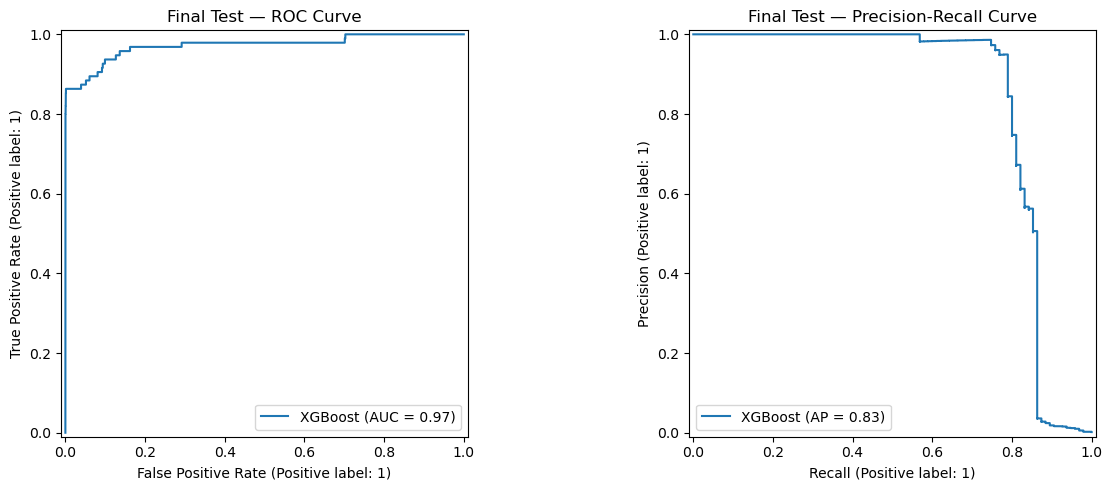

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_test_prob,
    name=model_name,
    ax=axes[0]
)

axes[0].set_title("Final Test — ROC Curve")

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_test_prob,
    name=model_name,
    ax=axes[1]
)

axes[1].set_title("Final Test — Precision-Recall Curve")

plt.tight_layout()
plt.show()

### 9.1 Test vs. validation: generalisation and remaining risk

At the same **0.50 threshold**, XGBoost's fraud precision increases from **90.91% (validation)** to **94.81% (test)**, while fraud recall decreases from **85.11%** to **76.84%**. Average precision decreases from **0.8881** to **0.8345**, and ROC-AUC decreases from **0.9805** to **0.9722**.

These differences may be due to natural variations in the data, as both the validation and test sets contain **only 94–95 fraudulent transactions.** This does not necessarily mean that the model is overfitting, nor does it guarantee that the model will achieve similar results when used in real-world situations.

The test results should be reported using the specified threshold of 0.50. Future work could include calculating confidence intervals or repeating the validation process with different data samples to check how consistent the results are. However, the existing test data should not be used again to make further changes or select the model.

In [53]:
y_final_val_prob = model_v3.predict_proba(X_val)[:, 1]

In [54]:
import pandas as pd

y_final_val_pred = (
    y_final_val_prob >= final_threshold
).astype(int)

comparison = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1", "ROC-AUC", "Average Precision"],
    "Validation": [
        precision_score(y_val, y_final_val_pred, zero_division=0),
        recall_score(y_val, y_final_val_pred),
        f1_score(y_val, y_final_val_pred),
        roc_auc_score(y_val, y_final_val_prob),
        average_precision_score(y_val, y_final_val_prob)
    ],
    "Test": [
        test_results["Precision"],
        test_results["Recall"],
        test_results["F1 Score"],
        test_results["ROC-AUC"],
        test_results["Average Precision"]
    ]
})

display(comparison.round(4))

,Metric,Validation,Test
0,Precision,0.9091,0.9481
1,Recall,0.8511,0.7684
2,F1,0.8791,0.8488
3,ROC-AUC,0.9805,0.9722
4,Average Precision,0.8881,0.8345


### 9.2 Final Validation–Test Comparison: What the Last Table Shows

The final code table compares **the same fitted XGBoost model at the same decision threshold (0.50)** on validation and held-out test observations. The purpose is to check whether the model performs consistently on different data, rather than changing the threshold based on the test results.

| Metric | Validation | Test | Interpretation |
|---|---:|---:|---|
| Precision | **90.91%** | **94.81%** | Most transactions identified as fraud are actually fraudulent in both datasets. Test precision is slightly higher. |
| Recall | **85.11%** | **76.84%** | The model misses more fraudulent transactions in the test dataset.|
| F1 score | **87.91%** | **84.88%** | The overall balance between precision and recall decreases slightly on the test data. |
| ROC-AUC | **0.9805** | **0.9722** | The model continues to distinguish well between fraudulent and legitimate transactions, although the score decreases slightly. |
| Average precision | **0.8881** | **0.8345** | 	
The model's ability to identify fraud across different thresholds is slightly lower on the test data. |

**Key reading:** The test set includes only **95 fraudulent records**; **73 are identified and 22 missed**. Since the number of fraud cases is relatively small, even a few incorrect predictions can noticeably change the recall score. These differences do not automatically mean the model is overfitting or that the results are statistically significant.

**Decision:** This study keeps the prediction threshold at **0.50** throughout the evaluation. Overall, the results show that XGBoost can distinguish between fraudulent and legitimate transactions effectively and produces a high percentage of correct fraud alerts. However, it still misses some fraudulent transactions, which remains an important risk.

## 10. Study Limitations

### 10.1 Historical, anonymised dataset

The dataset contains transactions from approximately two days in September 2013, so it does not represent modern payment systems. The features `V1–V28` are anonymised PCA components, which makes it difficult to understand what each feature represents and explain why a transaction is classified as fraud. It also limits the ability to check whether the model treats different demographic groups fairly. Therefore, the results should not be assumed to reflect how well the model would detect fraud today without testing it on newer data.

### 10.2 Limited number of fraudulent transactions and evaluation uncertainty

After duplicate removal, only **473** of **283,726** transactions are labelled fraud. The validation and test sets contain **94** and **95** frauds, respectively. Since the number of fraud cases is small, the model's performance, especially recall, may change depending on which transactions are included in the dataset. The notebook does not calculate confidence intervals or perform repeated cross-validation to check the consistency of the results.

### 10.3 Duplicate handling may remove meaningful observations

The notebook removes **1,081** identical rows, including **19** originally labelled fraud. However, identical transaction details do not always mean that the same transaction has been recorded twice. Some genuine transactions may have exactly the same details. Since transaction IDs are not available, it is difficult to confirm whether all removed records were actual duplicates. Comparing the results before and after duplicate removal would help determine whether this decision affected model performance.

### 10.4 Models use different imbalance-handling strategies

Logistic Regression and Random Forest are fitted on a randomly undersampled training set, whereas XGBoost is trained on the original training data with `scale_pos_weight=10`. This means the models are trained using different approaches to handle the imbalance between legitimate and fraudulent transactions. Although this allows us to compare the overall modelling approaches, it does not provide a completely equal comparison of the algorithms themselves. XGBoost may perform better partly because it retains more training data.

### 10.5 Validation method and real-world performance

The dataset is divided randomly while maintaining a similar proportion of fraudulent and legitimate transactions in each set. However, this does not show how well the model would perform on future transactions or detect new fraud patterns over time. The EDA graphs also use the full dataset for descriptive analysis. Therefore, important decisions about feature selection and model development should be checked using training data only to avoid information leakage.

### 10.6 Fixed decision threshold and missing cost information

The study uses a fixed prediction threshold of **0.50** to classify transactions as fraudulent or legitimate. However, this does not prove that 0.50 is the best threshold for real-world fraud detection. The dataset does not provide information about financial losses caused by fraud, the cost of investigating suspicious transactions, or the impact of false alerts on customers. The study also does not include probability calibration or real-world deployment testing. Therefore, it is not possible to conclude that the model provides the best financial outcome.

### 10.7 No systematic hyperparameter search

The model settings were manually selected in the notebook rather than being tested through a systematic optimisation process. No grid search, random search or nested cross-validation is documented. Therefore, the models should not be described as fully hyperparameter-tuned or as using the best possible settings. Further testing could help identify settings that improve model performance.

## 11. Conclusion and Key Findings

**Answer to the research question:** The results show that all three models can detect fraudulent transactions much better than simply predicting every transaction as legitimate. However, the models differ in how many fraudulent transactions they detect and how many false alerts they produce. Among the three **evaluated configurations**, **XGBoost** gives the best validation precision (**90.91%**), F1 (**87.91%**), and average precision (**0.8881**); Logistic Regression achieves the highest validation recall (**89.36%**) at the fixed 0.50 threshold.

On the **held-out test set**, XGBoost achieves **94.81% precision**, **76.84% recall**, **84.88% F1**, **0.9722 ROC-AUC**, and **0.8345 average precision** at threshold **0.50**. The confusion matrix corresponds to **73 frauds detected, 22 frauds missed, and 4 legitimate transactions incorrectly flagged**.

**Main takeaway:** High overall accuracy alone is not enough to determine whether a fraud detection model performs well. Looking at precision, recall, F1-score and Average Precision gives a clearer picture of how effectively the model identifies fraudulent transactions. Although XGBoost achieves strong results, it still misses approximately **23% of fraudulent transactions** in the test dataset. Therefore, the balance between detecting fraud and reducing false alerts must be considered when evaluating the model.

**Future work:** 

+ Compare different methods of handling class imbalance using consistent training and validation processes.

+ Perform systematic hyperparameter tuning to find better model settings using training and validation data only.

+ Use confidence intervals to understand how reliable and consistent the model's results are.

+ Examine probability calibration and test different prediction thresholds based on financial costs and investigation resources.

+ Test the model using newer transaction data to check whether it can detect future fraud patterns and perform well on data from other sources.

**Scope of the study:** The results demonstrate how well the models perform on this historical public dataset using the preprocessing and evaluation methods described in the notebook. However, they do not prove that the model is ready for real-world use, can reduce actual financial losses, or uses the most financially suitable prediction threshold.